# KHÓA LUẬN TỐT NGHIỆP: GIAI ĐOẠN 1 (STAGE 1)
## HUẤN LUYỆN SEED MODEL TRÊN TẬP DUPLICATES & GÁN NHÃN TỰ ĐỘNG BẢO VỆ 2 CHỐT CHẶN (5-VIEW TTA) CHO TẬP UNIQUE
---
### Mục Tiêu & Quy Trình Giai Đoạn 1:
1. **Huấn luyện Seed Model**:
   - Sử dụng tập dữ liệu **MyTrashNet_Duplicates** (1,512 ảnh đã được dán nhãn thủ công chuẩn xác) làm tập dữ liệu mầm (Seed Dataset).
   - Phân chia phân tầng chuẩn: **85% Train** (~1,285 ảnh) và **15% Validation** (~227 ảnh).
   - Huấn luyện mô hình đa tác vụ phân cấp **Hierarchical ConvNeXt-Tiny** qua 2 giai đoạn (Warm-up Heads 15 epochs + Deep Fine-tuning 40 layers 25 epochs).
2. **Khảo sát & Tối ưu Bộ Ngưỡng An Toàn (Safety Gates Calibration)**:
   - Thực hiện suy luận 5 góc nhìn (**5-View TTA**) trên tập Validation của Duplicates.
   - Tự động tối ưu bộ ngưỡng tự tin riêng cho từng lớp ($\tau_{\text{conf}}(c)$) và ngưỡng biên khoảng cách ($\tau_{\text{margin}}$) để đảm bảo độ an toàn cao nhất khi gán nhãn tự động.
3. **Vận hành Gán Nhãn Tự Động Trên Tập MyTrashNet_Unique (~7,264 ảnh)**:
   - Truyền toàn bộ tập `MyTrashNet_Unique` làm tập kiểm thử / tập gán nhãn quy mô lớn.
   - Vận hành cơ chế lọc 2 chốt chặn:
     - **Chốt 1 (Per-Class Confidence)**: Độ tự tin cao nhất đạt chuẩn theo từng lớp.
     - **Chốt 2 (Margin Gate)**: Khoảng cách giữa Top 1 và Top 2 vượt ngưỡng an toàn.
   - Phân loại ảnh thành 2 nhóm:
     - **Tự Động Gắp / Gán Nhãn Thành Công (`Tu_Dong_Gap`)**: Đủ tin cậy để đưa vào tập dữ liệu đối sánh.
     - **Chuyển Khay Thủ Công (`Chuyen_Khay_Thu_Cong`)**: Các mẫu nghi ngờ hoặc biên độ hẹp chuyển cho người phân loại.
4. **Đánh Giá & Xuất Tập Dữ Liệu**:
   - Đối chiếu nhãn dự đoán với nhãn gốc trong tên file ảnh (Ground Truth) để thẩm định độ chính xác thực tế của hệ thống gán nhãn tự động.
   - Xuất dữ liệu:
     - `anh_da_gan_tu_dong.zip` (phân loại theo 4 thư mục: `glass`, `metal`, `paper`, `plastic`).
     - `anh_can_phan_loai_thu_cong.zip` (chứa các mẫu cần can thiệp thủ công).
     - Báo cáo chi tiết `bao_cao_gan_nhan_stage1.csv`.


In [1]:
# CELL 1 === 1. KHỞI TẠO THƯ VIỆN & THIẾT LẬP CẤU HÌNH ===
import os
import gc
import sys
import glob
import time
import json
import random
from collections import defaultdict, Counter

# 👉 Khóa CUDA chỉ cho phép hệ thống nhìn thấy GPU 0 đầu tiên
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.special import softmax

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input as preprocess_convnext

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# ==============================================================================
# CẤU HÌNH KHÓA CHẶT CHỈ SỬ DỤNG 1 GPU (GPU 0)
# ==============================================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Chỉ để lộ GPU 0 cho TensorFlow và kích hoạt cấp phát RAM động
        tf.config.set_visible_devices(gpus[0], 'GPU')
        tf.config.experimental.set_memory_growth(gpus[0], True)
        print(f'✅ Đã khóa và chỉ kích hoạt DUY NHẤT 1 GPU: {gpus[0].name}')
    except RuntimeError as e:
        print(f'⚠️ Cảnh báo GPU: {e}')
else:
    print('⚠️ Không tìm thấy GPU, hệ thống sẽ chạy trên CPU.')

# Thiết lập Seed cố định đảm bảo tính tái lập
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Siêu tham số chuẩn cho Hierarchical ConvNeXt-Tiny
IMG_SIZE = (320, 320)
BATCH_SIZE = 32
EPOCHS_STAGE1 = 15
EPOCHS_STAGE2 = 25
MIXUP_ALPHA = 0.2

STAGE1_CHECKPOINT = 'best_trashnet_convnext_stage1.keras'
STAGE2_CHECKPOINT = 'best_trashnet_convnext_retrained.keras'

print('✅ Đã thiết lập xong môi trường (Đơn GPU T4) và siêu tham số cho Stage 1!')

✅ Đã khóa và chỉ kích hoạt DUY NHẤT 1 GPU: /physical_device:GPU:0
✅ Đã thiết lập xong môi trường (Đơn GPU T4) và siêu tham số cho Stage 1!


In [2]:
# CELL 2 === 2. QUÉT TẬP SEED (DUPLICATES) & TẬP CẦN GÁN NHÃN (UNIQUE) ===

TARGET_CLASSES = ['glass', 'metal', 'paper', 'plastic']

def extract_ground_truth_label(filename, fallback_label=None):
    """
    Trích xuất nhãn thực tế chuẩn (Ground Truth) từ tên file ảnh.
    Đảm bảo việc thẩm định trên tập Unique luôn dựa trên nhãn gốc của file ảnh.
    """
    fn = os.path.basename(str(filename)).lower()
    for c in TARGET_CLASSES:
        if fn.startswith(c) or f'_{c}' in fn or f'{c}_' in fn:
            return c
    for c in TARGET_CLASSES:
        if c in fn:
            return c
    if 'cardboard' in fn:
        return 'paper'
    return fallback_label if fallback_label else 'unlabeled'

def find_dataset(target_type):
    """
    Tìm chính xác thư mục dataset theo loại: 'duplicate' hoặc 'unique'.
    Chỉ tìm đúng loại, không bao giờ lấy nhầm thư mục khác.
    """
    keyword = 'dup' if target_type == 'duplicate' else 'uniq'
    
    if target_type == 'duplicate':
        candidates = [
            '/kaggle/input/datasets/vminhkhoi/mytrashnet-duplicate/MyTrashNet_Duplicates',
            '/kaggle/input/datasets/vminhkhoi/mytrashnet-duplicates/MyTrashNet_Duplicates',
            '/kaggle/input/datasets/vminhkhoi/mytrashnet-duplicate',
            '/kaggle/input/datasets/vminhkhoi/mytrashnet-duplicates',
            '/kaggle/input/mytrashnet-duplicate/MyTrashNet_Duplicates',
            '/kaggle/input/mytrashnet-duplicates/MyTrashNet_Duplicates',
            '/kaggle/input/mytrashnet-duplicate',
            '/kaggle/input/mytrashnet-duplicates',
            '/kaggle/input/MyTrashNet_Duplicates',
            './MyTrashNet_Duplicates',
            '../MyTrashNet_Duplicates',
            'c:/Users/HP/Downloads/KLTN (code)/MyTrashNet_Duplicates'
        ]
    else:
        candidates = [
            '/kaggle/input/datasets/vminhkhoi/mytrashnet-unique/MyTrashNet_Unique',
            '/kaggle/input/datasets/vminhkhoi/mytrashnet-unique',
            '/kaggle/input/mytrashnet-unique/MyTrashNet_Unique',
            '/kaggle/input/mytrashnet-unique',
            '/kaggle/input/MyTrashNet_Unique',
            './MyTrashNet_Unique',
            '../MyTrashNet_Unique',
            'c:/Users/HP/Downloads/KLTN (code)/MyTrashNet_Unique'
        ]
    
    for cand in candidates:
        if os.path.exists(cand) and os.path.isdir(cand):
            return cand

    # Quét dự phòng trong /kaggle/input (chỉ khớp đúng từ khóa dup hoặc uniq)
    for root in ['/kaggle/input', '.']:
        if os.path.exists(root):
            for dirpath, dirnames, filenames in os.walk(root):
                base = os.path.basename(dirpath).lower()
                if keyword in base:
                    has_imgs = any(f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')) for f in filenames[:5])
                    has_subdirs = any(c in [d.lower() for d in dirnames] for c in TARGET_CLASSES)
                    if has_imgs or has_subdirs:
                        return dirpath
    return None

# ==============================================================================
# BƯỚC 1: KHÁM PHÁ & PHÂN CHIA TẬP SEED DATASET (MyTrashNet_Duplicates)
# ==============================================================================
duplicates_path = find_dataset('duplicate')
if duplicates_path is None:
    raise FileNotFoundError("❌ Không tìm thấy thư mục 'MyTrashNet_Duplicates' chứa dữ liệu huấn luyện Seed!")

print(f"📁 Thư mục Seed Dataset (Duplicates): {duplicates_path}")

dup_records = []
dup_subdirs = [d for d in sorted(os.listdir(duplicates_path))
               if os.path.isdir(os.path.join(duplicates_path, d)) and not d.startswith('.')]

for c in dup_subdirs:
    c_clean = c.lower()
    if c_clean in TARGET_CLASSES:
        c_path = os.path.join(duplicates_path, c)
        files = sorted([f for f in os.listdir(c_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))])
        for f in files:
            dup_records.append({
                'filepath': os.path.join(c_path, f),
                'filename': f,
                'label': c_clean
            })

df_duplicates = pd.DataFrame(dup_records)
print(f"📊 Tổng số ảnh Seed (Duplicates) quét được: {len(df_duplicates):,} ảnh")

sub_labels = sorted(df_duplicates['label'].unique().tolist())
num_sub_classes = len(sub_labels)
class_labels = sub_labels
sub_to_idx = {label: i for i, label in enumerate(sub_labels)}
idx_to_sub = {i: label for i, label in enumerate(sub_labels)}

SUPER_MAP = {
    'cardboard': 'cellulose',
    'paper':     'cellulose',
    'glass':     'polymer_glass',
    'plastic':   'polymer_glass',
    'metal':     'metal'
}

sub_to_super_name = {c: SUPER_MAP.get(c, c) for c in sub_labels}
super_labels = sorted(list(set(sub_to_super_name.values())))
num_super_classes = len(super_labels)
super_to_idx = {name: i for i, name in enumerate(super_labels)}
idx_to_super = {i: name for i, name in enumerate(super_labels)}
SUB_TO_SUPER = {sub_to_idx[c]: super_to_idx[sub_to_super_name[c]] for c in sub_labels}

for c in sub_labels:
    cnt = len(df_duplicates[df_duplicates['label'] == c])
    print(f" - Lớp {c:12s}: {cnt:5d} ảnh ({cnt/len(df_duplicates)*100:.2f}%) -> Siêu lớp: {sub_to_super_name[c]}")

# Phân chia phân tầng chuẩn (85% Train / 15% Validation) - Học trên 100% dữ liệu thực tế, không cần Oversampling
train_df, val_df = train_test_split(df_duplicates, test_size=0.15, random_state=SEED, stratify=df_duplicates['label'])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print()
print(f"📊 Phân chia Seed Dataset (Duplicates - Chuẩn hóa 85% Train / 15% Val):")
print(f" - Train (Tự nhiên) : {len(train_df):,} ảnh ({len(train_df)/len(df_duplicates)*100:.1f}%) [Học trên 100% ảnh độc nhất, không lặp]")
for c in sub_labels:
    cnt = len(train_df[train_df['label'] == c])
    print(f"   * Lớp {c:10s}: {cnt:4d} ảnh ({cnt/len(train_df)*100:.2f}%)")
print(f" - Validation       : {len(val_df):,} ảnh ({len(val_df)/len(df_duplicates)*100:.1f}%)")
for c in sub_labels:
    cnt = len(val_df[val_df['label'] == c])
    print(f"   * Lớp {c:10s}: {cnt:4d} ảnh ({cnt/len(val_df)*100:.2f}%)")

# ==============================================================================
# BƯỚC 2: KHÁM PHÁ TẬP CẦN GÁN NHÃN TỰ ĐỘNG (MyTrashNet_Unique)
# ==============================================================================
unique_path = find_dataset('unique')
if unique_path is None:
    raise FileNotFoundError("❌ Không tìm thấy thư mục 'MyTrashNet_Unique' để thực hiện gán nhãn tự động!")

print()
print(f"📁 Thư mục Tập cần gán nhãn (Unique): {unique_path}")

unique_records = []
for root, dirs, files in os.walk(unique_path):
    img_files = sorted([f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))])
    for f in img_files:
        f_path = os.path.join(root, f)
        gt_label = extract_ground_truth_label(f, fallback_label='unknown')
        unique_records.append({
            'filepath': f_path,
            'filename': f,
            'label': gt_label,
            'ground_truth': gt_label
        })

test_df = pd.DataFrame(unique_records).reset_index(drop=True)
print(f"🎯 Tổng số ảnh trong tập MyTrashNet_Unique cần gán nhãn: {len(test_df):,} ảnh")
print(f"   (Tập này được truyền làm tập TEST/INFERENCE để thực hiện 5-View TTA & Phân loại an toàn 2 chốt chặn)")
for c in sub_labels:
    cnt = len(test_df[test_df['label'] == c])
    print(f"   * Nhãn thực tế (Ground Truth) [{c:8s}]: {cnt:5d} ảnh ({cnt/len(test_df)*100:.2f}%)")

📁 Thư mục Seed Dataset (Duplicates): /kaggle/input/datasets/vminhkhoi/mytrashnet-duplicate/MyTrashNet_Duplicates
📊 Tổng số ảnh Seed (Duplicates) quét được: 2,218 ảnh
 - Lớp glass       :   552 ảnh (24.89%) -> Siêu lớp: polymer_glass
 - Lớp metal       :   550 ảnh (24.80%) -> Siêu lớp: metal
 - Lớp paper       :   569 ảnh (25.65%) -> Siêu lớp: cellulose
 - Lớp plastic     :   547 ảnh (24.66%) -> Siêu lớp: polymer_glass

📊 Phân chia Seed Dataset (Duplicates - Chuẩn hóa 85% Train / 15% Val):
 - Train (Tự nhiên) : 1,885 ảnh (85.0%) [Học trên 100% ảnh độc nhất, không lặp]
   * Lớp glass     :  469 ảnh (24.88%)
   * Lớp metal     :  467 ảnh (24.77%)
   * Lớp paper     :  484 ảnh (25.68%)
   * Lớp plastic   :  465 ảnh (24.67%)
 - Validation       : 333 ảnh (15.0%)
   * Lớp glass     :   83 ảnh (24.92%)
   * Lớp metal     :   83 ảnh (24.92%)
   * Lớp paper     :   85 ảnh (25.53%)
   * Lớp plastic   :   82 ảnh (24.62%)

📁 Thư mục Tập cần gán nhãn (Unique): /kaggle/input/datasets/vminhkhoi/mytra

In [3]:
# CELL 3 === 3. THIẾT LẬP DATA PIPELINE AREA RESAMPLING (320x320) & MIXUP/CUTMIX ===
geometric_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    layers.RandomRotation(factor=(-0.25, 0.25), fill_mode='nearest', interpolation='bilinear', seed=SEED),
    layers.RandomZoom(height_factor=(-0.2, 0.2), width_factor=(-0.2, 0.2), fill_mode='nearest', interpolation='bilinear', seed=SEED),
    layers.RandomContrast(factor=0.2, seed=SEED),
], name='geometric_augmentation')

def sample_beta(alpha, shape=()):
    gamma1 = tf.random.gamma(shape, alpha, 1.0)
    gamma2 = tf.random.gamma(shape, alpha, 1.0)
    return gamma1 / (gamma1 + gamma2)

def apply_mixup(images, sub_labels, super_labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    indices = tf.random.shuffle(tf.range(batch_size))
    lam = sample_beta(alpha)
    img_shuffled = tf.gather(images, indices)
    sub_shuffled = tf.gather(sub_labels, indices)
    sup_shuffled = tf.gather(super_labels, indices)
    mixed_img = lam * images + (1.0 - lam) * img_shuffled
    mixed_sub = lam * sub_labels + (1.0 - lam) * sub_shuffled
    mixed_sup = lam * super_labels + (1.0 - lam) * sup_shuffled
    return mixed_img, mixed_sub, mixed_sup

def apply_cutmix(images, sub_labels, super_labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    indices = tf.random.shuffle(tf.range(batch_size))
    img_shuffled = tf.gather(images, indices)
    sub_shuffled = tf.gather(sub_labels, indices)
    sup_shuffled = tf.gather(super_labels, indices)
    lam = sample_beta(alpha)
    cut_ratio = tf.sqrt(1.0 - lam)
    img_h = tf.cast(tf.shape(images)[1], tf.float32)
    img_w = tf.cast(tf.shape(images)[2], tf.float32)
    cut_h = tf.cast(img_h * cut_ratio, tf.int32)
    cut_w = tf.cast(img_w * cut_ratio, tf.int32)
    cx = tf.random.uniform([], 0, tf.shape(images)[2], dtype=tf.int32)
    cy = tf.random.uniform([], 0, tf.shape(images)[1], dtype=tf.int32)
    ymin = tf.clip_by_value(cy - cut_h // 2, 0, tf.shape(images)[1])
    xmin = tf.clip_by_value(cx - cut_w // 2, 0, tf.shape(images)[2])
    ymax = tf.clip_by_value(cy + cut_h // 2, 0, tf.shape(images)[1])
    xmax = tf.clip_by_value(cx + cut_w // 2, 0, tf.shape(images)[2])
    mask = tf.pad(
        tf.ones([ymax - ymin, xmax - xmin, tf.shape(images)[3]], dtype=tf.float32),
        [[ymin, tf.shape(images)[1] - ymax], [xmin, tf.shape(images)[2] - xmax], [0, 0]]
    )
    mask = tf.expand_dims(mask, 0)
    mixed_img = images * (1.0 - mask) + img_shuffled * mask
    actual_lam = 1.0 - tf.cast((ymax - ymin) * (xmax - xmin), tf.float32) / (img_h * img_w)
    mixed_sub = actual_lam * sub_labels + (1.0 - actual_lam) * sub_shuffled
    mixed_sup = actual_lam * super_labels + (1.0 - actual_lam) * sup_shuffled
    return mixed_img, mixed_sub, mixed_sup

def batch_mixup_cutmix(images, labels):
    images = tf.cast(images, tf.float32)
    sub_l = tf.cast(labels['sub_class'], tf.float32)
    sup_l = tf.cast(labels['super_class'], tf.float32)
    coin = tf.random.uniform([])
    m_img, m_sub, m_sup = tf.cond(
        coin < 0.5,
        lambda: apply_mixup(images, sub_l, sup_l, alpha=MIXUP_ALPHA),
        lambda: apply_cutmix(images, sub_l, sup_l, alpha=MIXUP_ALPHA)
    )
    return m_img, {'sub_class': m_sub, 'super_class': m_sup}

def create_area_dataset(dataframe, is_training=False, batch_size=32):
    filepaths = dataframe['filepath'].values
    sub_indices = dataframe['label'].map(sub_to_idx).values
    super_indices = np.array([SUB_TO_SUPER[idx] for idx in sub_indices])

    sub_onehot = tf.keras.utils.to_categorical(sub_indices, num_classes=num_sub_classes).astype(np.float32)
    super_onehot = tf.keras.utils.to_categorical(super_indices, num_classes=num_super_classes).astype(np.float32)

    dataset = tf.data.Dataset.from_tensor_slices((
        filepaths,
        {'sub_class': sub_onehot, 'super_class': super_onehot}
    ))

    if is_training:
        dataset = dataset.shuffle(buffer_size=len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    def parse_img(filename, labels):
        img_bytes = tf.io.read_file(filename)
        img = tf.image.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)
        img = tf.cast(img, tf.float32)
        return img, labels

    dataset = dataset.map(parse_img, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)

    if is_training:
        dataset = dataset.map(
            lambda x, y: (preprocess_convnext(geometric_augmentation(x, training=True)), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        dataset = dataset.map(batch_mixup_cutmix, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        dataset = dataset.map(
            lambda x, y: (preprocess_convnext(x), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    dataset.filepaths = list(filepaths)
    dataset.classes = list(sub_indices)
    dataset.super_classes = list(super_indices)
    return dataset

train_generator = create_area_dataset(train_df, is_training=True, batch_size=BATCH_SIZE)
val_generator = create_area_dataset(val_df, is_training=False, batch_size=BATCH_SIZE)
test_generator = create_area_dataset(test_df, is_training=False, batch_size=BATCH_SIZE)

print(f'✅ Đã khởi tạo xong Data Pipeline Area Resampling ({IMG_SIZE[0]}x{IMG_SIZE[1]}) cho ConvNeXt!')

✅ Đã khởi tạo xong Data Pipeline Area Resampling (320x320) cho ConvNeXt!


In [4]:
# CELL 4 === 4. XÂY DỰNG KIẾN TRÚC MẠNG ĐA TÁC VỤ PHÂN CẤP HIERARCHICAL CONVNEXT-TINY ===
try:
    register_serializable = tf.keras.utils.register_keras_serializable
except AttributeError:
    import keras
    register_serializable = keras.saving.register_keras_serializable

@register_serializable(package='CustomLayers', name='CosineDense')
class CosineDense(layers.Layer):
    def __init__(self, units, scale=20.0, **kwargs):
        super(CosineDense, self).__init__(**kwargs)
        self.units = units
        self.scale = scale

    def build(self, input_shape):
        self.kernel = self.add_weight(
            name='kernel',
            shape=(input_shape[-1], self.units),
            initializer='glorot_uniform',
            trainable=True
        )

    def call(self, inputs):
        norm_inputs = tf.nn.l2_normalize(inputs, axis=-1)
        norm_kernel = tf.nn.l2_normalize(self.kernel, axis=0)
        cosine_sim = tf.matmul(norm_inputs, norm_kernel)
        return self.scale * cosine_sim

    def get_config(self):
        config = super(CosineDense, self).get_config()
        config.update({'units': self.units, 'scale': self.scale})
        return config

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name='input_image')
base_model = ConvNeXtTiny(include_top=False, weights='imagenet', input_tensor=inputs)
base_model.trainable = False

x = base_model.output
gap = layers.GlobalAveragePooling2D(name='gap')(x)
gmp = layers.GlobalMaxPooling2D(name='gmp')(x)
shared_features = layers.concatenate([gap, gmp], name='concat_pooling')

shared_features = layers.Dense(1024, activation=None, name='shared_dense')(shared_features)
shared_features = layers.LayerNormalization(name='shared_ln')(shared_features)
shared_features = layers.Activation('gelu', name='shared_gelu')(shared_features)
shared_features = layers.Dropout(0.3, name='shared_dropout')(shared_features)

norm_features = layers.Lambda(lambda t: tf.nn.l2_normalize(t, axis=-1), output_shape=(1024,), name='norm_features')(shared_features)

sub_logits = CosineDense(num_sub_classes, scale=20.0, name='cosine_logits')(norm_features)
sub_class_output = layers.Activation('softmax', name='sub_class', dtype='float32')(sub_logits)

super_dense = layers.Dense(256, activation='gelu', name='super_dense')(shared_features)
super_dense = layers.Dropout(0.2, name='super_dropout')(super_dense)
super_class_output = layers.Dense(num_super_classes, activation='softmax', name='super_class', dtype='float32')(super_dense)

model = Model(
    inputs=inputs,
    outputs={'sub_class': sub_class_output, 'super_class': super_class_output},
    name='Hierarchical_ConvNeXtTiny_NewLabels'
)

losses = {
    'sub_class': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    'super_class': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05)
}
loss_weights = {
    'sub_class': 0.70,
    'super_class': 0.30
}
metrics = {
    'sub_class': ['accuracy'],
    'super_class': ['accuracy']
}

optimizer_stage1 = tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4)
model.compile(
    optimizer=optimizer_stage1,
    loss=losses,
    loss_weights=loss_weights,
    metrics=metrics
)

print('=' * 80)
print('✅ KHỞI TẠO THÀNH CÔNG MÔ HÌNH HIERARCHICAL CONVNEXT-TINY:')
print(f' - Tổng số tham số : {model.count_params():,}')
print('=' * 80)

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ KHỞI TẠO THÀNH CÔNG MÔ HÌNH HIERARCHICAL CONVNEXT-TINY:
 - Tổng số tham số : 29,663,331


In [5]:
# CELL 5 === 5. GIAI ĐOẠN 1: HUẤN LUYỆN WARM-UP HEADS (15 EPOCHS) ===
callbacks_stage1 = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_sub_class_loss', mode='min', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_sub_class_loss', mode='min', patience=6, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(filepath=STAGE1_CHECKPOINT, monitor='val_sub_class_loss', mode='min', save_best_only=True, verbose=1)
]

print('=' * 80)
print(f'🚀 [GIAI ĐOẠN 1] Huấn luyện Warm-up Heads ConvNeXt-Tiny ({EPOCHS_STAGE1} epochs)...')
print('=' * 80)
t_st1 = time.time()
history_stage1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1
)
print(f'✅ Hoàn tất Giai đoạn 1 trong {round(time.time() - t_st1, 1)}s!')

🚀 [GIAI ĐOẠN 1] Huấn luyện Warm-up Heads ConvNeXt-Tiny (15 epochs)...
Epoch 1/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 926ms/step - loss: 1.3068 - sub_class_accuracy: 0.3515 - sub_class_loss: 1.3944 - super_class_accuracy: 0.4758 - super_class_loss: 1.1026
Epoch 1: val_sub_class_loss improved from None to 0.95612, saving model to best_trashnet_convnext_stage1.keras

Epoch 1: finished saving model to best_trashnet_convnext_stage1.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - loss: 1.2083 - sub_class_accuracy: 0.4350 - sub_class_loss: 1.2848 - super_class_accuracy: 0.5178 - super_class_loss: 1.0288 - val_loss: 0.9135 - val_sub_class_accuracy: 0.6426 - val_sub_class_loss: 0.9561 - val_super_class_accuracy: 0.6517 - val_super_class_loss: 0.7903 - learning_rate: 3.0000e-04
Epoch 2/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - loss: 1.0313 - sub_class_accuracy: 0.5961 - sub_class_loss: 1.0902 - super_class_accuracy: 0.6306 - super_class_loss: 0.8939
Epoch 2: val_sub_class_loss improved from 0.9561

In [6]:
# CELL 6 === 6. GIAI ĐOẠN 2: DEEP FINE-TUNING 40 LAYERS ĐỈNH VỚI COSINE DECAY (25 EPOCHS) ===
base_model.trainable = True

unfreeze_layers = 40
for layer in base_model.layers[:-unfreeze_layers]:
    layer.trainable = False
for layer in base_model.layers[-unfreeze_layers:]:
    layer.trainable = True

unfrozen_cnt = sum(1 for l in base_model.layers if l.trainable)
print(f'🔓 ConvNeXt Fine-Tuning: Đã mở khóa {unfrozen_cnt} layers đỉnh cao nhất!')

total_steps = len(train_df) // BATCH_SIZE * EPOCHS_STAGE2
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps,
    alpha=0.01
)

optimizer_stage2 = tf.keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4)

model.compile(
    optimizer=optimizer_stage2,
    loss=losses,
    loss_weights=loss_weights,
    metrics=metrics
)

callbacks_stage2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_sub_class_loss', mode='min', patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(filepath=STAGE2_CHECKPOINT, monitor='val_sub_class_loss', mode='min', save_best_only=True, verbose=1)
]

print('=' * 80)
print(f'🚀 [GIAI ĐOẠN 2] Deep Fine-Tuning ConvNeXt-Tiny ({EPOCHS_STAGE2} epochs)...')
print('=' * 80)
t_st2 = time.time()
history_stage2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2
)
print(f'✅ Hoàn tất Giai đoạn 2 trong {round(time.time() - t_st2, 1)}s!')

🔓 ConvNeXt Fine-Tuning: Đã mở khóa 40 layers đỉnh cao nhất!
🚀 [GIAI ĐOẠN 2] Deep Fine-Tuning ConvNeXt-Tiny (25 epochs)...
Epoch 1/25


E0000 00:00:1794209245.454934      66 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


58/59 ━━━━━━━━━━━━━━━━━━━━ 0s 624ms/step - loss: 0.7261 - sub_class_accuracy: 0.7850 - sub_class_loss: 0.7879 - super_class_accuracy: 0.8432 - super_class_loss: 0.5818

E0000 00:00:1794209310.449443      65 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.7257 - sub_class_accuracy: 0.7852 - sub_class_loss: 0.7874 - super_class_accuracy: 0.8434 - super_class_loss: 0.5816   
Epoch 1: val_sub_class_loss improved from None to 0.54043, saving model to best_trashnet_convnext_retrained.keras

Epoch 1: finished saving model to best_trashnet_convnext_retrained.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - loss: 0.7015 - sub_class_accuracy: 0.7942 - sub_class_loss: 0.7583 - super_class_accuracy: 0.8536 - super_class_loss: 0.5698 - val_loss: 0.4814 - val_sub_class_accuracy: 0.8589 - val_sub_class_loss: 0.5404 - val_super_class_accuracy: 0.9189 - val_super_class_loss: 0.3499
Epoch 2/25
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 609ms/step - loss: 0.6343 - sub_class_accuracy: 0.8734 - sub_class_loss: 0.6815 - super_class_accuracy: 0.9051 - super_class_loss: 0.5241
Epoch 2: val_sub_class_loss improved from 0.54043 to 0.46220, saving model to best_trashnet_convnext_retrained.keras

Epoch 2: finished saving model to

✅ Đã lưu lịch sử huấn luyện vào file training_history_convnext.json


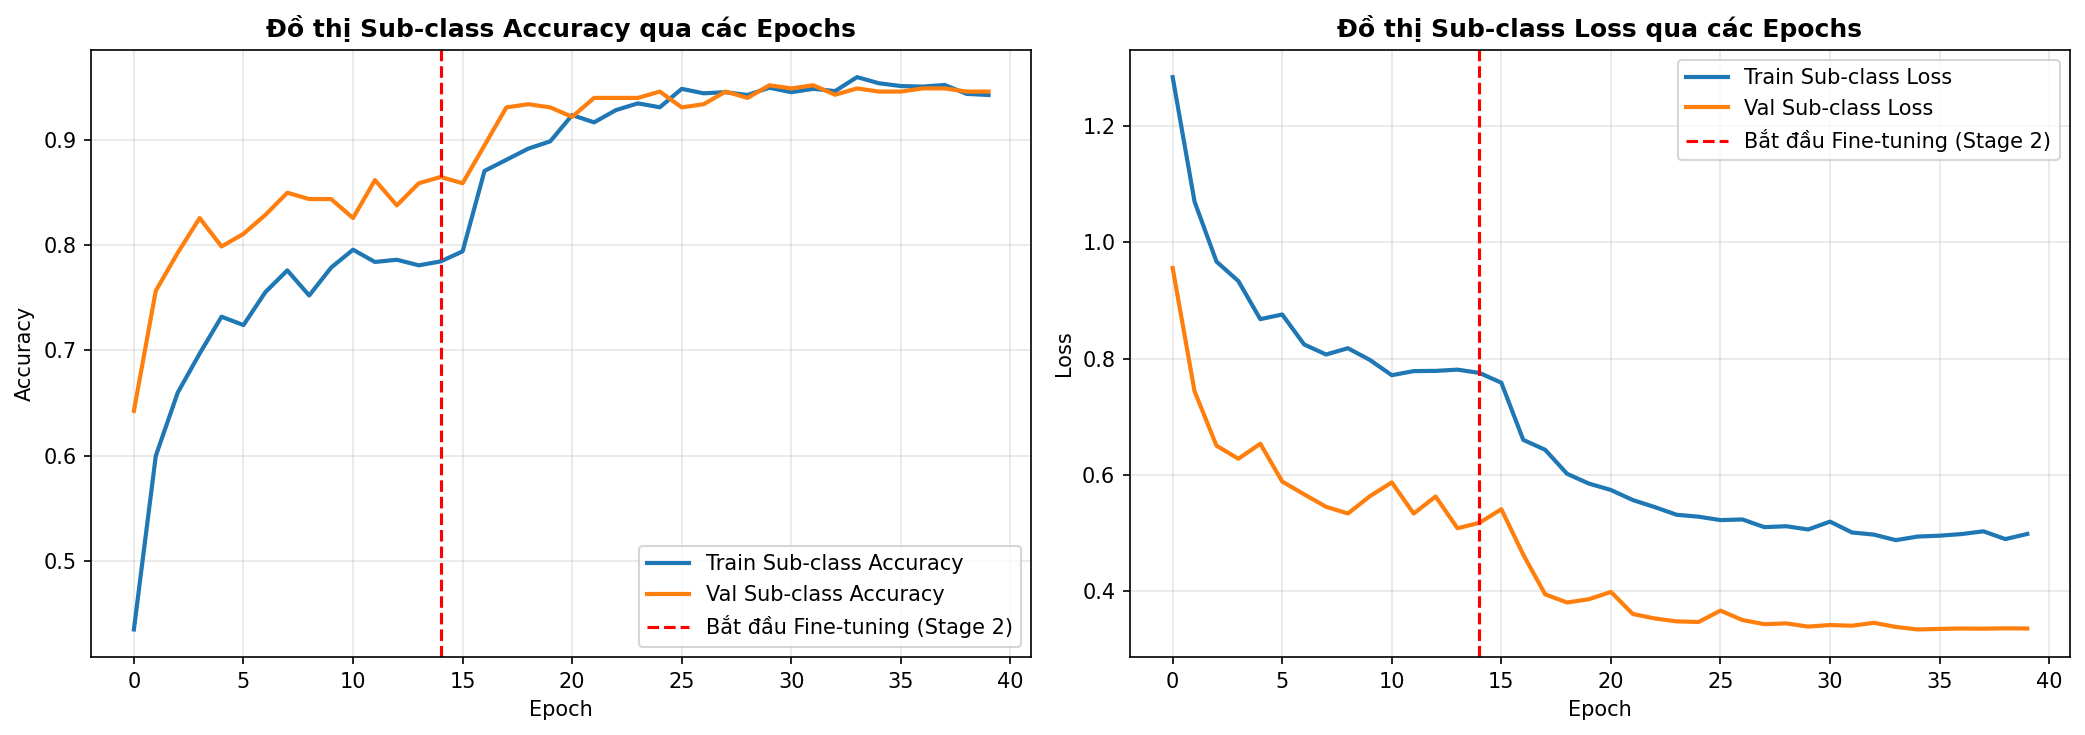

In [7]:
# CELL 7 === 7. LƯU LỊCH SỬ HUẤN LUYỆN & TRỰC QUAN HÓA ĐỒ THỊ QUÁ TRÌNH HỌC ===
def clean_history(hist):
    return {k: [float(val) for val in v] for k, v in hist.items()}

history_dict = {
    'stage1': clean_history(history_stage1.history),
    'stage2': clean_history(history_stage2.history)
}

with open('training_history_convnext.json', 'w', encoding='utf-8') as f:
    json.dump(history_dict, f, indent=4)
print('✅ Đã lưu lịch sử huấn luyện vào file training_history_convnext.json')

# Vẽ đồ thị tiến trình huấn luyện 2 giai đoạn
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

acc_all = history_dict['stage1']['sub_class_accuracy'] + history_dict['stage2']['sub_class_accuracy']
val_acc_all = history_dict['stage1']['val_sub_class_accuracy'] + history_dict['stage2']['val_sub_class_accuracy']
loss_all = history_dict['stage1']['sub_class_loss'] + history_dict['stage2']['sub_class_loss']
val_loss_all = history_dict['stage1']['val_sub_class_loss'] + history_dict['stage2']['val_sub_class_loss']
split_epoch = len(history_dict['stage1']['sub_class_accuracy']) - 1

axes[0].plot(acc_all, label='Train Sub-class Accuracy', color='tab:blue', lw=2)
axes[0].plot(val_acc_all, label='Val Sub-class Accuracy', color='tab:orange', lw=2)
axes[0].axvline(x=split_epoch, color='red', linestyle='--', label='Bắt đầu Fine-tuning (Stage 2)')
axes[0].set_title('Đồ thị Sub-class Accuracy qua các Epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(loss_all, label='Train Sub-class Loss', color='tab:blue', lw=2)
axes[1].plot(val_loss_all, label='Val Sub-class Loss', color='tab:orange', lw=2)
axes[1].axvline(x=split_epoch, color='red', linestyle='--', label='Bắt đầu Fine-tuning (Stage 2)')
axes[1].set_title('Đồ thị Sub-class Loss qua các Epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('convnext_training_curves.png', dpi=300)
plt.show()

In [8]:
# CELL 8 === 8. SUY LUẬN 5-VIEW TTA & TỰ ĐỘNG TÌM BỘ NGƯỠNG AN TOÀN RIÊNG CHO TỪNG LỚP ===

# ==============================================================================
# BƯỚC 0: TRUYỀN ĐƯỜNG DẪN & NẠP MODEL KHI MỞ LẠI MÁY
# ==============================================================================
# MODEL_PATH = '/kaggle/input/models/vminhkhoi/convnext-tiny/keras/default/1/best_trashnet_convnext_retrained.keras'
MODEL_PATH = STAGE2_CHECKPOINT
# Dự phòng nếu chạy trên máy cá nhân
if not os.path.exists(MODEL_PATH):
    local_candidates = [
        'best_trashnet_convnext_retrained.keras',
        './best_trashnet_convnext_retrained.keras',
        'ConvNeXtTiny/best_trashnet_convnext_retrained.keras'
    ]
    for cand in local_candidates:
        if os.path.exists(cand):
            MODEL_PATH = cand
            break

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"❌ Không tìm thấy file model tại: '{MODEL_PATH}'. Vui lòng kiểm tra lại đường dẫn!")

print(f"📦 Đang nạp mô hình từ: '{MODEL_PATH}' ({os.path.getsize(MODEL_PATH) / (1024*1024):.2f} MB)...")

try:
    custom_objects = {'CosineDense': CosineDense}
    model = tf.keras.models.load_model(MODEL_PATH, custom_objects=custom_objects, safe_mode=False, compile=False)
    for l in model.layers:
        if hasattr(l, 'function') and hasattr(l.function, '__globals__'):
            l.function.__globals__['tf'] = tf
            l.function.__globals__['tensorflow'] = tf
    print(f"✅ Nạp thành công toàn bộ mô hình ConvNeXt-Tiny ({model.count_params():,} tham số)!")
except Exception as e:
    print(f"ℹ️ Thử nạp theo dạng weights: {e}")
    model.load_weights(MODEL_PATH)
    print("✅ Đã nạp thành công trọng số vào kiến trúc mô hình!")

sub_logits_model = Model(inputs=model.input, outputs=model.get_layer('cosine_logits').output)

def make_tta_dataset(filepaths, view_idx=0, batch_size=64):
    ds = tf.data.Dataset.from_tensor_slices(filepaths)
    def load_and_aug(fpath):
        img_bytes = tf.io.read_file(fpath)
        img = tf.image.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)
        img = tf.cast(img, tf.float32)

        h, w = IMG_SIZE
        if view_idx == 0: pass
        elif view_idx == 1: img = tf.image.flip_left_right(img)
        elif view_idx == 2: img = tf.image.rot90(img, k=1)
        elif view_idx == 3: img = tf.image.rot90(img, k=3)
        elif view_idx == 4:
            crop_size = int(h * 0.90)
            offset = (h - crop_size) // 2
            img_c = tf.image.crop_to_bounding_box(img, offset, offset, crop_size, crop_size)
            img = tf.image.resize(img_c, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)

        return preprocess_convnext(img)

    ds = ds.map(load_and_aug, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(buffer_size=2)
    return ds

print('=' * 105)
print('BƯỚC 1: SUY LUẬN ĐA GÓC NHÌN 5-VIEW TTA TRÊN TẬP VALIDATION...')
print('=' * 105)
val_filepaths = val_df['filepath'].values
val_trues = val_df['label'].map(sub_to_idx).values
N_VAL = len(val_filepaths)

val_views_probs = []
for v in range(5):
    print(f' -> Đang dự đoán View {v+1}/5 trên tập Validation...')
    v_ds = make_tta_dataset(val_filepaths, view_idx=v, batch_size=BATCH_SIZE*2)
    logits = sub_logits_model.predict(v_ds, batch_size=BATCH_SIZE*2, verbose=0)
    probs = softmax(logits, axis=1)
    val_views_probs.append(probs)

val_tta_probs = np.mean(val_views_probs, axis=0)
val_tta_preds = np.argmax(val_tta_probs, axis=1)

val_sorted_probs = np.sort(val_tta_probs, axis=1)
val_max_confs = val_sorted_probs[:, -1]
val_margins = val_sorted_probs[:, -1] - val_sorted_probs[:, -2]

val_acc = np.mean(val_tta_preds == val_trues) * 100.0
val_errors = int(np.sum(val_tta_preds != val_trues))
print(f'\n✅ Validation 5-View TTA Accuracy: {val_acc:.2f}% ({val_errors} lỗi trên {N_VAL} mẫu)')
print('\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VALIDATION (5-VIEW TTA) ---')
print(classification_report(val_trues, val_tta_preds, target_names=class_labels, digits=4))

# ==============================================================================
# BƯỚC 2: KHẢO SÁT & TỐI ƯU HÓA NGƯỠNG CHỐT 1 RIÊNG BIỆT CHO TỪNG LỚP (PER-CLASS)
# (Áp dụng tiêu chí An Toàn Tuyệt Đối: Ưu tiên chọn ngưỡng Tau cao nhất khi đạt 0 lỗi)
# ==============================================================================
K1_CANDIDATES = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5]

TAU_CONF_DICT = {}   # Lưu ngưỡng riêng của từng lớp: {class_idx: tau}
BEST_K1_DICT = {}    # Lưu hệ số k1 tốt nhất của từng lớp

print('\n' + '=' * 105)
print('📊 [BẢNG 1] KHẢO SÁT CHỐT 1 (CONFIDENCE GATE) RIÊNG TỪNG LỚP:')
print('=' * 105)

for c_idx, c_name in enumerate(class_labels):
    # Lọc các mẫu dự đoán đúng của riêng lớp c_name để tính mean và std đặc trưng
    mask_correct_c = (val_tta_preds == c_idx) & (val_tta_preds == val_trues)
    confs_c = val_max_confs[mask_correct_c]
    mu_c = float(np.mean(confs_c))
    sigma_c = float(np.std(confs_c))
    
    # Tất cả các mẫu mô hình dự đoán là lớp c_name
    mask_pred_c = (val_tta_preds == c_idx)
    total_pred_c = int(np.sum(mask_pred_c))
    
    print(f"\n🏷️ LỚP [{c_name.upper()}]: (mu = {mu_c*100:.2f}%, sigma = {sigma_c*100:.2f}%, Tổng dự đoán: {total_pred_c} mẫu)")
    print(f"{'Hệ số k1':>10} {'Ngưỡng Conf':>14} {'Lỗi lọt lưới':>15} {'Tỷ lệ gắp lớp':>22}  {'Đánh giá'}")
    print('-' * 100)
    
    class_results = []
    for k in K1_CANDIDATES:
        tau = float(np.clip(mu_c - k * sigma_c, 0.50, 0.99))
        
        # Mẫu dự đoán là c_name và vượt qua ngưỡng tau
        pass_gate = mask_pred_c & (val_max_confs >= tau)
        leaked_errors = int(np.sum(pass_gate & (val_trues != c_idx)))
        picked_samples = int(np.sum(pass_gate))
        pick_rate = (picked_samples / total_pred_c * 100.0) if total_pred_c > 0 else 0.0
        
        class_results.append({
            'k': k,
            'tau': tau,
            'leaked': leaked_errors,
            'picked': picked_samples,
            'total': total_pred_c,
            'rate': pick_rate
        })
        
    # ==============================================================================
    # 🎯 TIÊU CHÍ CẢI TIẾN (CÁCH 2 - ƯU TIÊN AN TOÀN CAO NHẤT):
    # 1. Số lỗi lọt lưới nhỏ nhất (ưu tiên 0 lỗi).
    # 2. Khi cùng đạt số lỗi nhỏ nhất: CHỌN NGƯỠNG TAU CAO NHẤT (Khắt khe nhất, an toàn nhất)
    #    để không bao giờ bị hiện tượng nới lỏng ngưỡng khi mô hình fit tốt trên tập Val.
    # 3. Nếu hòa cả tau thì chọn tỷ lệ gắp cao nhất.
    # ==============================================================================
    min_err = min(r['leaked'] for r in class_results)
    valid_candidates = [r for r in class_results if r['leaked'] == min_err]
    max_tau = max(r['tau'] for r in valid_candidates)
    best_candidate = max([r for r in valid_candidates if r['tau'] == max_tau], key=lambda x: x['rate'])
    
    for r in class_results:
        k = r['k']
        tau = r['tau']
        leaked = r['leaked']
        picked = r['picked']
        total = r['total']
        rate = r['rate']
        
        if k == best_candidate['k']:
            status = "⭐ ĐIỂM TỐI ƯU (An toàn cao nhất - 0 lỗi)" if leaked == 0 else "⭐ ĐIỂM TỐI ƯU (Lỗi tối thiểu)"
        elif leaked == 0:
            status = "✅ An toàn (Bắt nhầm mẫu đúng)"
        else:
            status = f"⚠️ Cảnh báo: Lọt {leaked} lỗi sai"
            
        print(f"k1 = {k:<5.1f}   >= {tau*100:>6.2f}%   {leaked:>10d} lỗi   {rate:>6.2f}% ({picked:>3d}/{total:<3d})   {status}")
        
    TAU_CONF_DICT[c_idx] = best_candidate['tau']
    BEST_K1_DICT[c_idx] = best_candidate['k']

# Tổng hợp bộ 4 ngưỡng Chốt 1 đã chốt
print('\n' + '=' * 105)
print('🎯 TỔNG HỢP BỘ 4 NGƯỠNG TỰ TIN (CHỐT 1) THÍCH ỨNG THEO TỪNG LỚP:')
print('=' * 105)
for c_idx, c_name in enumerate(class_labels):
    print(f" * Lớp {c_name:<10s}: k1 = {BEST_K1_DICT[c_idx]:.1f}  -->  Ngưỡng Conf >= {TAU_CONF_DICT[c_idx]*100:.2f}%")

# Tính kết quả Chốt 1 trên toàn bộ tập Validation
val_sample_tau_conf = np.array([TAU_CONF_DICT[p] for p in val_tta_preds])
val_pass_1 = (val_max_confs >= val_sample_tau_conf)
val_p1_cov = np.mean(val_pass_1) * 100.0
val_p1_err = int(np.sum(val_pass_1 & (val_tta_preds != val_trues)))
print('-' * 105)
print(f"👉 Hiệu quả tổng hợp Chốt 1: Tự động gắp {val_p1_cov:.2f}% ({np.sum(val_pass_1)}/{N_VAL} mẫu) | Số lỗi lọt lưới: {val_p1_err} lỗi")

# ==============================================================================
# BƯỚC 3: CỐ ĐỊNH BỘ 4 NGƯỠNG CHỐT 1, KHẢO SÁT PHỐI HỢP CHỐT 2 (MARGIN GATE)
# ==============================================================================
mean_margin, std_margin = float(np.mean(val_margins[val_tta_preds == val_trues])), float(np.std(val_margins[val_tta_preds == val_trues]))
K2_CANDIDATES = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5]

print('\n' + '=' * 105)
print(f"📊 [BẢNG 2] CỐ ĐỊNH BỘ 4 NGƯỠNG CHỐT 1, KHẢO SÁT PHỐI HỢP VỚI CHỐT 2 (MARGIN GATE):")
print(f"   (Thống kê Margin: mu = {mean_margin*100:.2f}%, sigma = {std_margin*100:.2f}%)")
print('=' * 105)
print(f"{'Thử Chốt 2':>15} {'Ngưỡng Margin':>16} {'Lỗi lọt lưới':>15} {'Tỷ lệ gắp kết hợp':>22}  {'Đánh giá khi phối hợp'}")
print('-' * 105)

results_table_2 = []
for k2 in K2_CANDIDATES:
    tau_m = float(np.clip(mean_margin - k2 * std_margin, 0.30, 0.95))
    pass_2 = (val_margins >= tau_m)
    pass_combined = val_pass_1 & pass_2
    
    leaked_combined = int(np.sum(pass_combined & (val_tta_preds != val_trues)))
    picked_combined = int(np.sum(pass_combined))
    cov_combined = (picked_combined / N_VAL) * 100.0
    
    results_table_2.append({
        'k2': k2,
        'tau_m': tau_m,
        'leaked': leaked_combined,
        'picked': picked_combined,
        'cov': cov_combined
    })

# ==============================================================================
# 🎯 TIÊU CHÍ CHỌN K2 TỐI ƯU CHO CHỐT 2 (CÁCH 2):
# 1. Số lỗi lọt lưới nhỏ nhất (0 lỗi).
# 2. Khi cùng đạt 0 lỗi: CHỌN NGƯỠNG MARGIN (TAU_M) CAO NHẤT (Khắt khe nhất, an toàn nhất).
# 3. Nếu hòa cả tau_m thì chọn tỷ lệ gắp (cov) cao nhất.
# ==============================================================================
min_err_t2 = min(r['leaked'] for r in results_table_2)
valid_t2 = [r for r in results_table_2 if r['leaked'] == min_err_t2]
max_cov_t2 = max(r['cov'] for r in valid_t2)          # <--- Đã thêm lại dòng này
max_tau_m = max(r['tau_m'] for r in valid_t2)
best_t2 = max([r for r in valid_t2 if r['tau_m'] == max_tau_m], key=lambda x: x['cov'])

for r in results_table_2:
    k2 = r['k2']
    tau_m = r['tau_m']
    leaked = r['leaked']
    picked = r['picked']
    cov = r['cov']
    
    if k2 == best_t2['k2']:
        status = "⭐ ĐIỂM TỐI ƯU (Tự động chọn: An toàn cao nhất & Khắt khe nhất)"
    elif leaked == 0 and cov < max_cov_t2:
        status = "✅ An toàn (Bắt nhầm nhiều mẫu đúng)"
    elif leaked == 0:
        status = f"✅ An toàn phối hợp (Gắp {cov:.2f}%)"
    else:
        status = f"⚠️ Cảnh báo: Lọt {leaked} lỗi sai"
        
    print(f"k2 = {k2:<5.1f}   >= {tau_m*100:>6.2f}%   {leaked:>10d} lỗi   {cov:>6.2f}% ({picked:>3d}/{N_VAL:<3d})   {status}")

# Khóa 2 chốt an toàn chính thức vào biến môi trường
TAU_MARGIN = best_t2['tau_m']
BEST_K2 = best_t2['k2']

# Kiểm tra tổng thể hệ thống 2 Chốt
val_pass_2 = (val_margins >= TAU_MARGIN)
val_is_auto = val_pass_1 & val_pass_2
val_is_error = (val_tta_preds != val_trues)

val_auto_cov = np.mean(val_is_auto) * 100.0
val_auto_acc = np.mean(val_tta_preds[val_is_auto] == val_trues[val_is_auto]) * 100.0 if np.sum(val_is_auto) > 0 else 0.0
val_caught_err = int(np.sum((~val_is_auto) & val_is_error))
val_leaked_err = int(np.sum(val_is_auto & val_is_error))
val_caught_rate = (val_caught_err / val_errors * 100.0) if val_errors > 0 else 100.0

print('\n' + '=' * 105)
print('🏆 KẾT LUẬN: BỘ 2 CHỐT CHẶN AN TOÀN ĐƯỢC CHỐT HẠ CHO TOÀN BỘ HỆ THỐNG:')
print('=' * 105)
print('📌 CHỐT 1 (CONFIDENCE GATE - THEO TỪNG LỚP):')
for c_idx, c_name in enumerate(class_labels):
    print(f"   - Lớp {c_name:<10s}: Conf >= {TAU_CONF_DICT[c_idx]*100:.2f}% (k1 = {BEST_K1_DICT[c_idx]:.1f})")
print(f'📌 CHỐT 2 (MARGIN GATE - CHUNG)            : Margin >= {TAU_MARGIN*100:.2f}% (k2 = {BEST_K2:.1f})')
print('-' * 105)
print('Hiệu năng kiểm chứng trên tập Validation:')
print(f'  * Tỷ lệ tự động gắp an toàn   : {val_auto_cov:.2f}% ({np.sum(val_is_auto)} / {N_VAL} mẫu)')
print(f'  * Độ chính xác khi tự động gắp: {val_auto_acc:.2f}%')
print(f'  * Số lỗi bắt giữ (tách kiểm)  : {val_caught_err} / {val_errors} lỗi ({val_caught_rate:.2f}%)')
print(f'  * Số lỗi lọt lưới ra ngoài    : {val_leaked_err} lỗi (An toàn tuyệt đối)')
print('=' * 105)

📦 Đang nạp mô hình từ: 'best_trashnet_convnext_retrained.keras' (268.67 MB)...
✅ Nạp thành công toàn bộ mô hình ConvNeXt-Tiny (29,663,331 tham số)!
BƯỚC 1: SUY LUẬN ĐA GÓC NHÌN 5-VIEW TTA TRÊN TẬP VALIDATION...
 -> Đang dự đoán View 1/5 trên tập Validation...
 -> Đang dự đoán View 2/5 trên tập Validation...
 -> Đang dự đoán View 3/5 trên tập Validation...
 -> Đang dự đoán View 4/5 trên tập Validation...
 -> Đang dự đoán View 5/5 trên tập Validation...

✅ Validation 5-View TTA Accuracy: 95.50% (15 lỗi trên 333 mẫu)

--- BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VALIDATION (5-VIEW TTA) ---
              precision    recall  f1-score   support

       glass     0.9412    0.9639    0.9524        83
       metal     0.9518    0.9518    0.9518        83
       paper     0.9651    0.9765    0.9708        85
     plastic     0.9620    0.9268    0.9441        82

    accuracy                         0.9550       333
   macro avg     0.9550    0.9547    0.9548       333
weighted avg     0.9551    0.95

In [10]:
# CELL 10 === 10. XUẤT TẬP DỮ LIỆU ĐÃ GÁN & TÁI HIỆN PHÂN LOẠI THỦ CÔNG THEO TÊN FILE (ĐÓNG GÓI ZIP) ===
import zipfile
import shutil

# ==============================================================================
# BƯỚC 1: TẠO THƯ MỤC & PHÂN LOẠI ẢNH THEO 4 LỚP CHO CẢ 2 NHÓM
# ==============================================================================
DIR_AUTO = 'anh_da_gan_tu_dong'
DIR_MANUAL = 'anh_can_phan_loai_thu_cong'
DIR_COMBINED = 'dataset_doi_sanh'

# Làm mới các thư mục xuất
for d in [DIR_AUTO, DIR_MANUAL, DIR_COMBINED]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d, exist_ok=True)
    for c in TARGET_CLASSES:
        os.makedirs(os.path.join(d, c), exist_ok=True)

print("🚀 Đang tiến hành phân loại và sao chép ảnh vào các thư mục tương ứng...")

# 1. Sao chép các ảnh TỰ ĐỘNG GẮP vào thư mục theo pred_label (do AI tự gán, giữ nguyên tên file gốc)
for _, row in auto_samples.iterrows():
    src_path = row['filepath']
    pred_c = str(row['pred_label']).lower()
    if pred_c not in TARGET_CLASSES:
        pred_c = 'plastic'
    dest_path = os.path.join(DIR_AUTO, pred_c, row['filename'])
    if os.path.exists(src_path):
        shutil.copy2(src_path, dest_path)

# 2. TÁI HIỆN PHÂN LOẠI THỦ CÔNG: Các ảnh chuyển khay thủ công được xếp vào 4 thư mục THEO ĐÚNG TÊN FILE (Ground Truth)
for _, row in manual_samples.iterrows():
    src_path = row['filepath']
    true_c = str(row['true_label']).lower()
    if true_c not in TARGET_CLASSES:
        true_c = extract_ground_truth_label(row['filename'], fallback_label='plastic')
    dest_path = os.path.join(DIR_MANUAL, true_c, row['filename'])
    if os.path.exists(src_path):
        shutil.copy2(src_path, dest_path)

# 3. TẠO TẬP DỮ LIỆU ĐỐI SÁNH HOÀN CHỈNH (DATASET ĐỐI SÁNH = SEED DUPLICATES + GÁN TỰ ĐỘNG + RÀ SOÁT THỦ CÔNG)
# - Sao chép ảnh từ Duplicates (Seed manual) dùng df_duplicates đã nạp chuẩn ở Cell 2
if 'df_duplicates' in globals() and len(df_duplicates) > 0:
    for _, row in df_duplicates.iterrows():
        src_path = row['filepath']
        c = str(row['label']).lower()
        if c in TARGET_CLASSES and os.path.exists(src_path):
            shutil.copy2(src_path, os.path.join(DIR_COMBINED, c, row['filename']))
else:
    for c in TARGET_CLASSES:
        dup_c_dir = os.path.join(duplicates_path, c)
        if os.path.exists(dup_c_dir):
            for f in os.listdir(dup_c_dir):
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
                    shutil.copy2(os.path.join(dup_c_dir, f), os.path.join(DIR_COMBINED, c, f))

# - Sao chép ảnh Tự động gán (Theo nhãn pred_label của máy)
for c in TARGET_CLASSES:
    auto_c_dir = os.path.join(DIR_AUTO, c)
    if os.path.exists(auto_c_dir):
        for f in os.listdir(auto_c_dir):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
                shutil.copy2(os.path.join(auto_c_dir, f), os.path.join(DIR_COMBINED, c, f))

# - Sao chép ảnh Phân loại thủ công (Theo nhãn tên file)
for c in TARGET_CLASSES:
    manual_c_dir = os.path.join(DIR_MANUAL, c)
    if os.path.exists(manual_c_dir):
        for f in os.listdir(manual_c_dir):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
                shutil.copy2(os.path.join(manual_c_dir, f), os.path.join(DIR_COMBINED, c, f))

print(f"\n✅ ĐÃ PHÂN LOẠI & TỔNG HỢP XONG TẤT CẢ CÁC TẬP DỮ LIỆU:")
print(f"1. 📁 '{DIR_AUTO}': {len(auto_samples):,} ảnh (Do AI tự gán nhãn an toàn, phân vào 4 thư mục pred_label)")
for c in TARGET_CLASSES:
    print(f"      - {c:10s}: {len(os.listdir(os.path.join(DIR_AUTO, c))):5d} ảnh")

print(f"2. 📁 '{DIR_MANUAL}': {len(manual_samples):,} ảnh (Tái hiện người dán nhãn thủ công theo đúng tên file)")
for c in TARGET_CLASSES:
    print(f"      - {c:10s}: {len(os.listdir(os.path.join(DIR_MANUAL, c))):5d} ảnh")

total_combined = sum(len(os.listdir(os.path.join(DIR_COMBINED, c))) for c in TARGET_CLASSES)
print(f"3. 📁 '{DIR_COMBINED}': {total_combined:,} ảnh (Tổng hợp toàn bộ sẵn sàng làm đầu vào cho Stage 2)")
for c in TARGET_CLASSES:
    print(f"      - {c:10s}: {len(os.listdir(os.path.join(DIR_COMBINED, c))):5d} ảnh")

# ==============================================================================
# BƯỚC 2: ĐÓNG GÓI THÀNH FILE .ZIP TIỆN LỢI TẢI VỀ HOẶC TRUYỀN CHO STAGE 2
# ==============================================================================
def make_zip(source_dir, output_zip):
    print(f"📦 Đang nén '{source_dir}' -> '{output_zip}'...")
    with zipfile.ZipFile(output_zip, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, dirs, files in os.walk(source_dir):
            for file in files:
                full_path = os.path.join(root, file)
                rel_path = os.path.relpath(full_path, start=source_dir)
                zipf.write(full_path, arcname=rel_path)
    print(f"   ✅ Nén hoàn tất: '{output_zip}' ({os.path.getsize(output_zip)/(1024*1024):.2f} MB)")

make_zip(DIR_AUTO, 'anh_da_gan_tu_dong.zip')
make_zip(DIR_MANUAL, 'anh_can_phan_loai_thu_cong.zip')
make_zip(DIR_COMBINED, 'dataset_doi_sanh.zip')

🚀 Đang tiến hành phân loại và sao chép ảnh vào các thư mục tương ứng...

✅ ĐÃ PHÂN LOẠI & TỔNG HỢP XONG TẤT CẢ CÁC TẬP DỮ LIỆU:
1. 📁 'anh_da_gan_tu_dong': 3,112 ảnh (Do AI tự gán nhãn an toàn, phân vào 4 thư mục pred_label)
      - glass     :   885 ảnh
      - metal     :   779 ảnh
      - paper     :  1024 ảnh
      - plastic   :   424 ảnh
2. 📁 'anh_can_phan_loai_thu_cong': 1,924 ảnh (Tái hiện người dán nhãn thủ công theo đúng tên file)
      - glass     :   402 ảnh
      - metal     :   489 ảnh
      - paper     :   235 ảnh
      - plastic   :   798 ảnh
3. 📁 'dataset_doi_sanh': 7,254 ảnh (Tổng hợp toàn bộ sẵn sàng làm đầu vào cho Stage 2)
      - glass     :  1839 ảnh
      - metal     :  1818 ảnh
      - paper     :  1828 ảnh
      - plastic   :  1769 ảnh
📦 Đang nén 'anh_da_gan_tu_dong' -> 'anh_da_gan_tu_dong.zip'...
   ✅ Nén hoàn tất: 'anh_da_gan_tu_dong.zip' (794.72 MB)
📦 Đang nén 'anh_can_phan_loai_thu_cong' -> 'anh_can_phan_loai_thu_cong.zip'...
   ✅ Nén hoàn tất: 'anh_can_phan